# Compare results across assays

This notebook calculates:
- Overlap of alleles and genes with results across three measured assays
- Distribution of ClinVar categories across three assays
- Comparison of actual readouts across assays
- Comparison of measured assays to the AI scores
- Comparison of assay readouts to the sequence features (plDDT and RSA)

In [103]:
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from matplotlib_venn import venn3
import numpy as np 
import matplotlib.colors as colors
import sys
sys.path.append("../../2_individual_assay_results")
from analyses_plot_utils import *

sys.path.append("../../1_allele_collection/2_analysis")
from plot_utils import *

In [69]:
allele_collection_outputs = "../../1_allele_collection/3_outputs"
dualipa_outputs = "../../2_individual_assay_results/dual_ipa/3_outputs"
imaging_outputs = "../../2_individual_assay_results/imaging/3_outputs"
ppi_outputs = "../1_inputs"

allele_col_df = pl.read_csv(f"{allele_collection_outputs}/varchamp_seq_confirm_alleles_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv", separator="\t", infer_schema_length=100000)
dualipa = pl.read_csv(f"{dualipa_outputs}/annotated_perturbation_scores.csv", infer_schema_length=100000)
imaging = pl.read_csv(f"{imaging_outputs}/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=100000)
ppi = pl.read_csv(f"{ppi_outputs}/sqY2H_variant_perturbation_scores_annotated_hit_TEMP.csv", infer_schema_length=100000)

## Process assay results

In [91]:
allele_col_df = allele_col_df.with_columns(
    pl.col("plddt").cast(pl.Float32).alias("plddt_f32"),
    pl.col("rsa").cast(pl.Float32).alias("rsa_f32")
).with_columns(
    (
        pl.when(pl.col("rsa_f32")<.1)
        .then(pl.lit("<10"))
        .when(pl.col("rsa_f32")>=.9)
        .then(pl.lit("$\geqslant$90"))
        .otherwise(pl.lit("10-90"))
    ).alias("RSA_Category"),
    (
        pl.when(pl.col("plddt_f32")<=50)
        .then(pl.lit("<=50"))
        .when((pl.col("plddt_f32")>50)&(pl.col("plddt_f32")<=70))
        .then(pl.lit("50-70"))
        .when((pl.col("plddt_f32")>70)&(pl.col("plddt_f32")<=90))
        .then(pl.lit("70-90"))
        .otherwise(pl.lit(">90"))
    ).alias("pLDDT_Category"),
    pl.col("clinvar_clnsig_clean").fill_null("5_Others")
)

In [92]:
al_dual_df = allele_col_df.join(
    dualipa.select([c for c in dualipa.columns if c not in allele_col_df.columns]),
    left_on="gene_variant",
    right_on="gene_allele",
    how="left"
)

al_dual_img = al_dual_df.join(
    imaging.select([c for c in imaging.columns if c not in allele_col_df.columns]),
    left_on="gene_variant",
    right_on="gene_allele",
    how="left",
    suffix="_img"
)

al_dual_img_ppi = al_dual_img.with_columns(
    pl.col("mut_id").cast(pl.Int64).alias("mut_id")
).join(
    ppi.select(["orf_id", "mut_id"]+[c for c in ppi.columns if c not in allele_col_df.columns]),
    left_on=["orf_id", "mut_id"],
    right_on=["orf_id", "mut_id"],
    how="left",
    suffix="_ppi"
)

al_dual_img_ppi

symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,entry_plate_orig,entry_well_orig,entry_plate_conso,entry_well_conso,entry_seq_pool,db_plate,db_well,n2h_plate,n2h_well,dualip_plate,dualip_well,mislocalization_plate,mislocalization_well,entry_sequenced,entry_sequence_confirmation_class,db_sequenced,db_sequence_confirmation_class,n2h_sequenced,n2h_sequence_confirmation_class,n2h_ref_sequence_confirmation_class,dualip_sequenced,dualip_sequence_confirmation_class,dualip_ref_sequence_confirmation_class,mislocalization_sequenced,mislocalization_sequence_confirmation_class,mislocalization_ref_sequence_confirmation_class,gene_variant,…,AUROC_BioRep1_GFP,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,AUROC_BioRep2_GFP,euclid_distance,num_edges,num_zero_wt,num_per_0.0,num_per_0.1,num_per_0.2,num_per_0.3,num_per_0.4,num_per_0.5,num_edge_0.0,num_edge_0.1,num_edge_0.2,num_edge_0.3,num_edge_0.4,num_edge_0.5,frac_per_0.0,frac_per_0.1,frac_per_0.2,frac_per_0.3,frac_per_0.4,frac_per_0.5,normalized_euclid_distance,allele_0,symbol_right_ppi,aa_change_right_ppi,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right,normalized_euclid_distance_normalized,hit
str,str,i64,i64,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,…,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,f64,f64,f64,i64
"""GBA1""","""ENSG00000177628""",2,6,"""CCSBVarC000001""","""ALE0000584""","""NC_000001.11:155240033:C:G""","""160G>C""","""Val54Leu""","""RC4""","""RC4_Mut_GDEh1026""","""H01""","""GDEhDisVCh_40054""","""F12""",2.0,"""RC4_Mut_GDDh1026""","""H01""",null,null,null,null,null,null,1.0,1.0,1.0,2.0,0.0,null,null,0.0,null,null,0.0,null,null,"""GBA1_Val54Leu""",…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""GBA1""","""ENSG00000177628""",2,73,"""CCSBVarC000002""","""ALE00000002""","""NC_000001.11:155238225:G:A""","""670C>T""","""Leu224Phe""","""RC4""","""RC4_Mut_GDEh1026""","""E01""","""GDEhDisVCh_40054""","""C12""",2.0,"""RC4_Mut_GDDh1026""","""E01""",null,null,null,null,null,null,1.0,1.0,1.0,1.0,0.0,null,null,0.0,null,null,0.0,null,null,"""GBA1_Leu224Phe""",…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""GBA1""","""ENSG00000177628""",2,113,"""CCSBVarC000003""","""ALE00000003""","""NC_000001.11:155237453:C:T""","""887G>A""","""Arg296Gln""","""RC4""","""RC4_Mut_GDEh1026""","""F01""","""GDEhDisVCh_40054""","""D12""",2.0,"""RC4_Mut_GDDh1026""","""F01""",null,null,null,null,null,null,1.0,1.0,1.0,7.0,0.0,null,null,0.0,null,null,0.0,null,null,"""GBA1_Arg296Gln""",…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""GBA1""","""ENSG00000177628""",2,231,"""CCSBVarC000004""","""ALE00000004""","""NC_000001.11:155235252:A:G""","""1448T>C""","""Leu483Pro""","""RC4""","""RC4_Mut_GDEh1026""","""G01""","""GDEhDisVCh_40054""","""E12""",2.0,"""RC4_Mut_GDDh1026""","""G01""",null,null,null,null,null,null,1.0,1.0,1.0,2.0,0.0,null,null,0.0,null,null,0.0,null,null,"""GBA1_Leu483Pro""",…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""GBA1""","""ENSG00000177628""",2,213510,"""CCSBVarC003869""","""ALE00003869""","""NC_000001.11:155239934:G:A""","""259C>T""","""Arg87Trp""","""CEGS2""","""CegsMutGDEh1035""","""B03""","""GDEhDisVCh_40054""","""B02""",2.0,"""CegsMutGDDh1035""",

Part 1: 10 genes, 53 variants


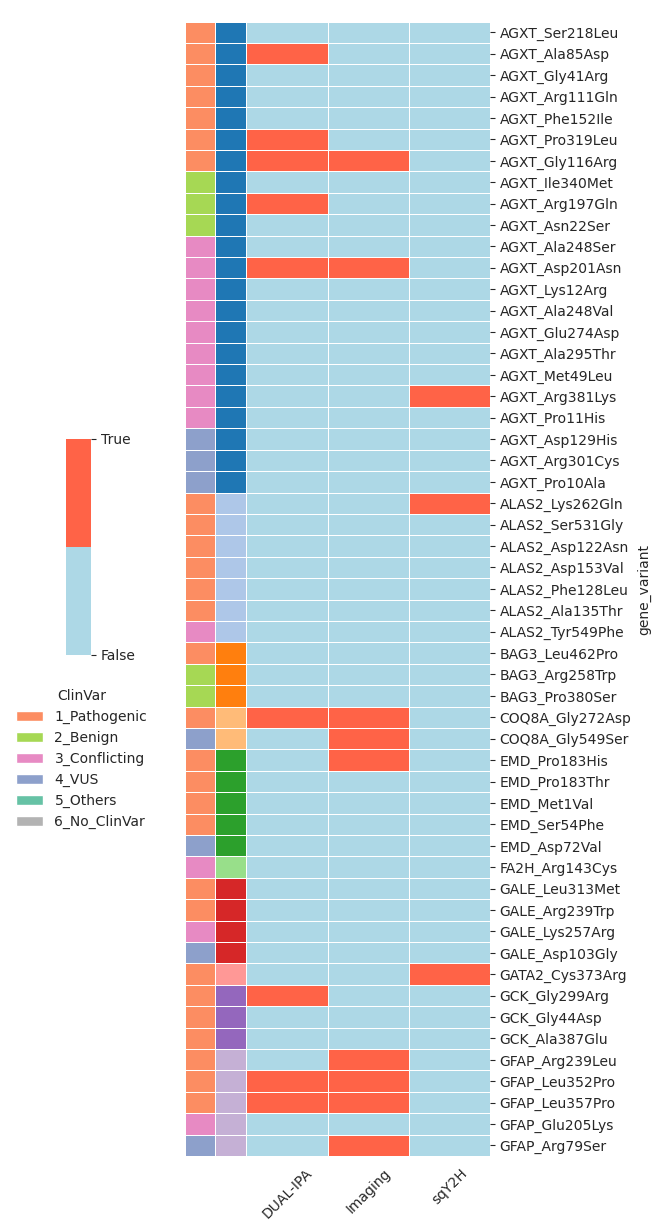

Part 2: 10 genes, 39 variants


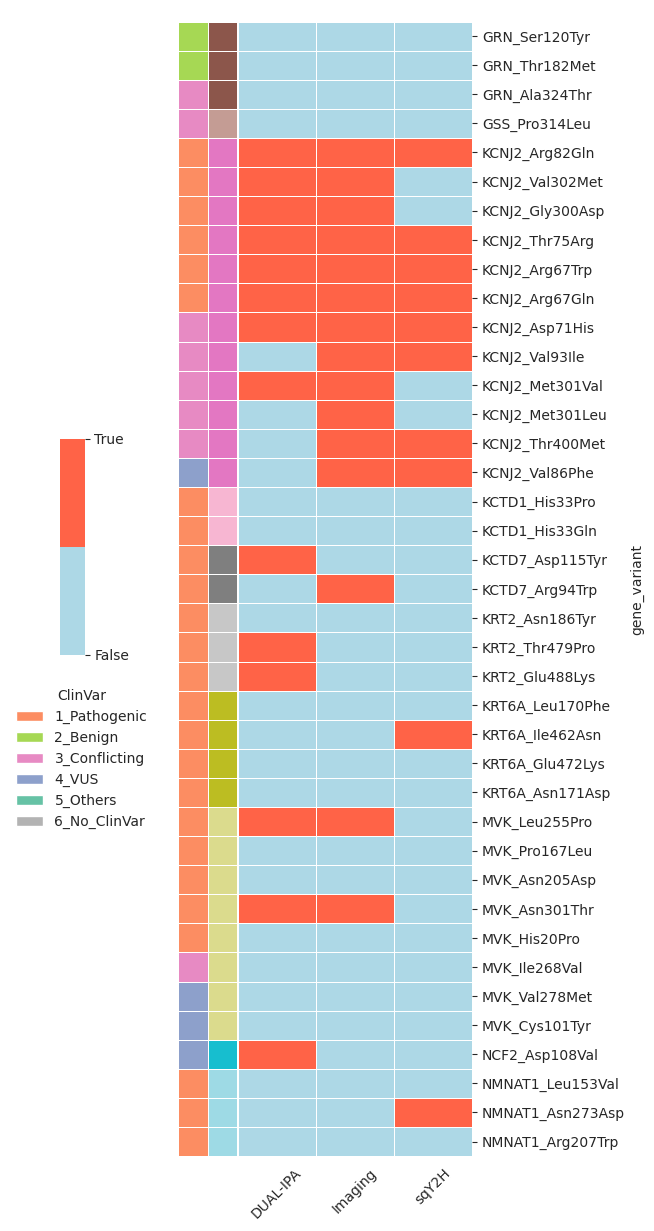

Part 2: 10 genes, 39 variants


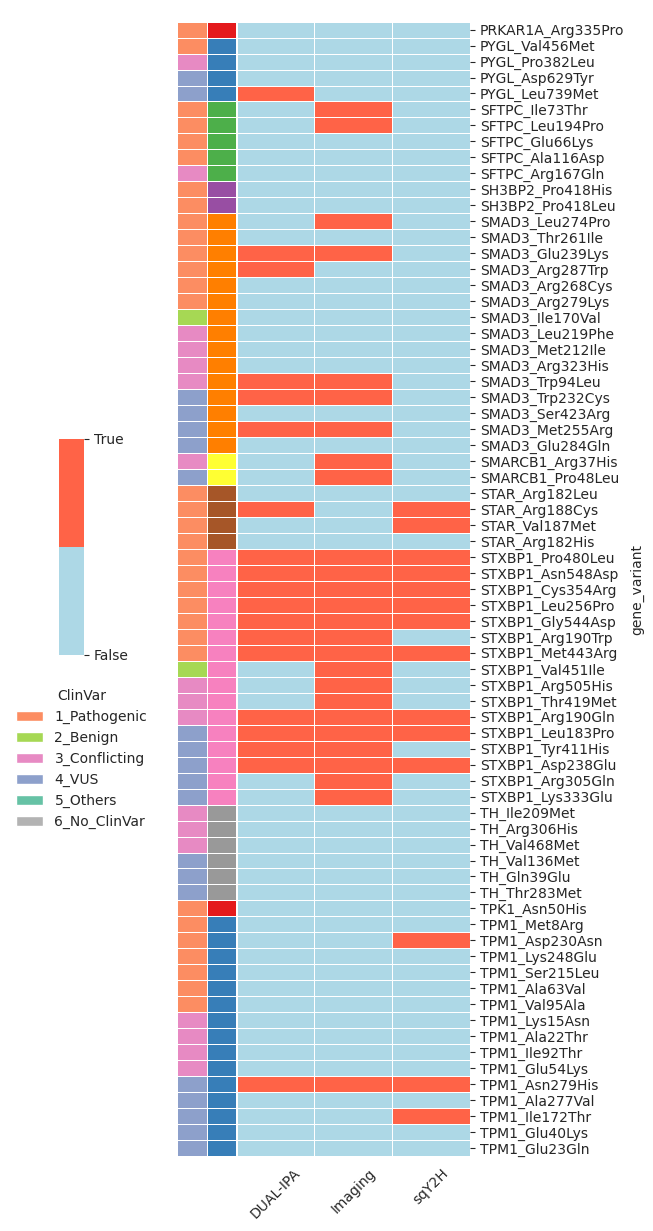

In [151]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

al_dual_img_ppi_intersect = al_dual_img_ppi.filter(
    pl.col("dualipa_abun_score").is_not_null(),
    pl.col("AUROC_Mean_GFP").is_not_null(),
    pl.col("normalized_euclid_distance").is_not_null()
).unique("gene_variant")

df = al_dual_img_ppi_intersect.select(
    pl.col(["symbol", "gene_variant", "dualipa_abun_change", "Altered_95th_perc_both_batches_GFP", "hit", "clinvar_clnsig_clean"])
).with_columns(
    pl.when(pl.col("dualipa_abun_change")==1)
    .then(pl.lit(1))
    .otherwise(pl.lit(0))
    .alias("DUAL-IPA"),
    pl.col("Altered_95th_perc_both_batches_GFP").cast(pl.Int8).alias("Imaging"),
    pl.col("hit").alias("sqY2H"),
).to_pandas()

# Ensure hit columns are ints
hit_cols = ['DUAL-IPA', 'Imaging', 'sqY2H']
df[hit_cols] = df[hit_cols].astype(int)

# Sort by gene symbol and ClinVar category
df_sorted = df.sort_values(['symbol', 'clinvar_clnsig_clean'])

# Create the hit matrix
matrix = df_sorted.set_index('gene_variant')[hit_cols]

# Row colors for ClinVar categories
lut = palette_dict["clinvar_clnsig_clean"]
row_colors_clinvar = df_sorted['clinvar_clnsig_clean'].map(lut).values

# Split genes into three groups while keeping alleles together
unique_genes = df_sorted['symbol'].unique()
n_genes = len(unique_genes)
split_point1 = n_genes // 3
split_point2 = 2 * n_genes // 3

genes_part1 = unique_genes[:split_point1]
genes_part2 = unique_genes[split_point1:split_point2]
genes_part3 = unique_genes[split_point2:]

# Create three separate datasets
df_part1 = df_sorted[df_sorted['symbol'].isin(genes_part1)]
df_part2 = df_sorted[df_sorted['symbol'].isin(genes_part2)]
df_part3 = df_sorted[df_sorted['symbol'].isin(genes_part3)]

def create_clustermap_part(df_part, part_name, genes_subset):
    # Create matrix for this part
    matrix_part = df_part.set_index('gene_variant')[hit_cols]
    
    # Row colors for ClinVar categories
    row_colors_clinvar_part = df_part['clinvar_clnsig_clean'].map(lut).values
    
    # Row colors for gene symbols (use consistent colors)
    gene_palette = sns.color_palette("tab20", 20) + sns.color_palette("Set1", n_genes-20)
    gene_lut = dict(zip(unique_genes, gene_palette))  # Keep all genes for consistent colors
    row_colors_genes_part = [gene_lut[gene] for gene in df_part['symbol']]
    
    # Combine row colors
    row_colors_part = [row_colors_clinvar_part, row_colors_genes_part]
    
    # Create clustermap
    g = sns.clustermap(
        matrix_part,
        row_cluster=False,
        col_cluster=False,
        cmap=cmap,
        linewidths=0.5,
        row_colors=row_colors_part,
        figsize=(5,12),
        colors_ratio=0.1,  # Increase from default 0.03 to make row colors wider
        cbar_pos=(-0.2, 0.45, 0.05, 0.18),
        cbar_kws={
            "ticks": [0, 1],
            "format": "%d",
            "format": lambda x, pos: "False" if x == 0 else "True",
        },
        dendrogram_ratio=0.01,  # Remove dendrogram space
        yticklabels=1
    )
    
    # Add legend for ClinVar categories
    handles = [Patch(facecolor=color, label=label) for label, color in lut.items()]
    g.ax_heatmap.legend(
        handles=handles,
        title='ClinVar',
        bbox_to_anchor=(-1., 0.35),
        loc='center left',
        frameon=False
    )
    g.ax_heatmap.tick_params(axis='x', rotation=45)
    # g.ax_heatmap.set_yticks(range(len(matrix_part)))
    # g.ax_heatmap.set_yticklabels(matrix_part.index, fontsize=10, va='center')

    # Change colorbar labels
    # g.ax_cbar.set_yticklabels(['False', 'True'])
    
    # plt.suptitle(f'{part_name} (Genes: {", ".join(genes_subset[:5])}{"..." if len(genes_subset) > 5 else ""})', 
    #              y=1., fontsize=14)
    plt.show()

# Create both parts
print(f"Part 1: {len(genes_part1)} genes, {len(df_part1)} variants")
create_clustermap_part(df_part1, "Part 1", genes_part1)

print(f"Part 2: {len(genes_part2)} genes, {len(df_part2)} variants")
create_clustermap_part(df_part2, "Part 2", genes_part2)

print(f"Part 2: {len(genes_part2)} genes, {len(df_part2)} variants")
create_clustermap_part(df_part3, "Part 3", genes_part3)

In [94]:
al_dual_img_ppi_union = al_dual_img_ppi.filter(
    (pl.col("dualipa_abun_score").is_not_null())
    | (pl.col("AUROC_Mean_GFP").is_not_null())
    | (pl.col("normalized_euclid_distance").is_not_null())
).unique("gene_variant")

al_dual_img_ppi_union.select(
    pl.col(["symbol", "gene_variant", "dualipa_abun_change", "Altered_95th_perc_both_batches_GFP", "hit", "clinvar_clnsig_clean"])
)

symbol,gene_variant,dualipa_abun_change,Altered_95th_perc_both_batches_GFP,hit,clinvar_clnsig_clean
str,str,i64,bool,i64,str
"""NR0B1""","""NR0B1_Arg425Ile""",-1,true,null,"""1_Pathogenic"""
"""KRAS""","""KRAS_Tyr71His""",null,false,null,"""1_Pathogenic"""
"""AGXT""","""AGXT_Leu359Pro""",1,null,null,"""1_Pathogenic"""
"""VHL""","""VHL_Arg126Trp""",null,null,0,"""1_Pathogenic"""
"""F9""","""F9_Ile7Phe""",null,false,null,"""2_Benign"""
…,…,…,…,…,…
"""GFAP""","""GFAP_Arg376Trp""",null,false,0,"""1_Pathogenic"""
"""GFAP""","""GFAP_Glu205Lys""",-1,false,0,"""3_Conflicting"""
"""MID1""","""MID1_Pro151Leu""",-1,null,null,"""4_VUS"""


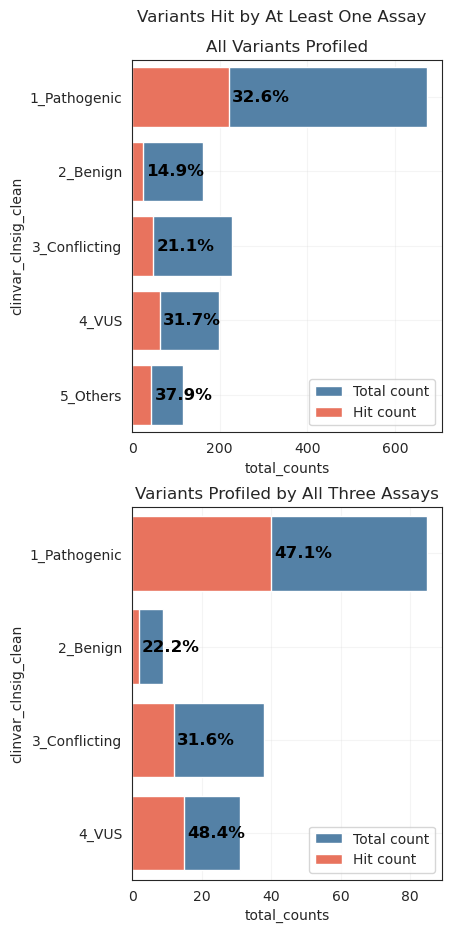

In [166]:
fig, axes = plt.subplots(2,1,figsize=(4,10))
plot_assay_hit_by_category(al_dual_img_ppi_union.with_columns(
    (
        (pl.col("dualipa_abun_change")==1)
        | (pl.col("Altered_95th_perc_both_batches_GFP"))
        | (pl.col("hit")==1)
    ).alias("hit_by_an_assay")
).filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS","5_Others","6_No_ClinVar"]) #pl.col("Gene")!="BRCA1" #
), "hit_by_an_assay", "clinvar_clnsig_clean", f"All Variants Profiled", ax=axes[0])
plot_assay_hit_by_category(al_dual_img_ppi_intersect.with_columns(
    (
        (pl.col("dualipa_abun_change")==1)
        | (pl.col("Altered_95th_perc_both_batches_GFP"))
        | (pl.col("hit")==1)
    ).alias("hit_by_an_assay")
).filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS","5_Others","6_No_ClinVar"]) #pl.col("Gene")!="BRCA1" #
), "hit_by_an_assay", "clinvar_clnsig_clean", f"Variants Profiled by All Three Assays", ax=axes[1])
plt.suptitle("Variants Hit by At Least One Assay")
plt.subplots_adjust(hspace=.2, top=.93)
plt.show()

## Calculate overlaps across assays

In [159]:
def plot_gene_level_summary(assay_df, assay, xlim=None, cat="clinvar_clnsig_clean", palette=None):
    gene_allele_cnts = assay_df.group_by(
        ["symbol"]
    ).len().rename(
        {"len": "total_counts_all"}
    ).sort("total_counts_all", descending=True)
    
    gene_allele_cat_cnts = assay_df.group_by(
        ["symbol", cat]
    ).len().rename(
        {"len": "total_counts"}
    )
    gene_allele_cat_hits = assay_df.filter(
        (pl.col(assay))
    ).group_by(
        ["symbol", cat]
    ).len().rename(
        {"len": "hit_counts"}
    )
    total_allele_hit_sum_df = gene_allele_cat_cnts.join(
        gene_allele_cat_hits,
        on=["symbol", cat],
        how="left"
    ).fill_null(0).with_columns(
        (pl.col("hit_counts") / pl.col("total_counts") * 100).alias("hit_perc")
    ).join(gene_allele_cnts, on="symbol").sort(
        "total_counts_all", "symbol", cat, 
        descending=[True, True, False]
    )
    genes_with_hits = total_allele_hit_sum_df.filter(pl.col("hit_perc")>0)["symbol"].unique()
    
    # Convert to pandas and sort
    total_allele_hit_sum_df = total_allele_hit_sum_df.to_pandas().reset_index(drop=True)
    n_genes = len(total_allele_hit_sum_df)
    
    # Add percentage labels
    # Get unique categories and their positions
    categories = total_allele_hit_sum_df[cat].unique()
    n_categories = len(categories)
    # Calculate bar positions for each category
    bar_height = 0.8 / n_categories  # Default seaborn bar height divided by number of categories
    
    # Dynamically scale figure size
    fig_height = n_genes * bar_height * n_categories / 2.5
    fig_width = 6  # Slightly wider to accommodate labels
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    if palette is None:
        palette = "Set2"
        
    # Create the barplots
    # Total counts (background bars)
    sns.barplot(
        data=total_allele_hit_sum_df, 
        y="symbol", 
        x="total_counts", 
        hue=cat,  # "clinvar_clnsig_clean"
        palette=palette,
        alpha=0.4,  # Make background bars slightly transparent
        ax=ax,
        # gap=.1,
        order=total_allele_hit_sum_df["symbol"].drop_duplicates(),
    )
    # Hit counts (foreground bars)
    sns.barplot(
        data=total_allele_hit_sum_df, 
        y="symbol", 
        x="hit_counts", 
        hue=cat,#"clinvar_clnsig_clean", 
        palette=palette,
        ax=ax,
        # gap=.1,
        order=total_allele_hit_sum_df["symbol"].drop_duplicates()
    )
    for i, gene in enumerate(total_allele_hit_sum_df["symbol"].unique()):
        gene_data = total_allele_hit_sum_df[total_allele_hit_sum_df["symbol"] == gene]
        for j, category in enumerate(categories):
            cat_data = gene_data[gene_data[cat] == category]
            if not cat_data.empty:
                # Calculate bar position
                bar_center = i + (j - (n_categories - 1) / 2) * bar_height
                # Get the hit percentage value
                hit_perc = cat_data["hit_perc"].iloc[0]
                hit_counts = cat_data["hit_counts"].iloc[0]
                # Add percentage label at the end of the hit_counts bar
                ax.text(
                    hit_counts + max(total_allele_hit_sum_df["hit_counts"]) * 0.01,  # Small offset
                    bar_center,
                    f"{hit_perc:.1f}%",
                    ha="left",
                    va="center",
                    fontsize=9 if n_genes > 20 else 10,
                    fontweight="bold"
                )
    
    # # Formatting
    ax.grid(alpha=0.2, axis='x')
    ax.set_xlabel("Count", fontsize=11)
    ax.set_ylabel("Gene Symbol", fontsize=11)
    ax.set_title(f"{assay}", fontsize=13)
    
    # Improve legend
    handles, labels = ax.get_legend_handles_labels()
    # Remove duplicate legend entries (seaborn creates duplicates with multiple barplots)
    unique_labels = []
    unique_handles = []
    for handle, label in zip(handles, labels):
        if label not in unique_labels:
            unique_labels.append(label)
            unique_handles.append(handle)
    
    ax.legend(unique_handles, unique_labels, 
              title=cat, 
              fontsize=10, 
              loc="lower right",
              framealpha=0.9)
    if xlim:
        ax.set_xlim(xlim)
        
    plt.tight_layout()
    plt.show()
    
    return total_allele_hit_sum_df

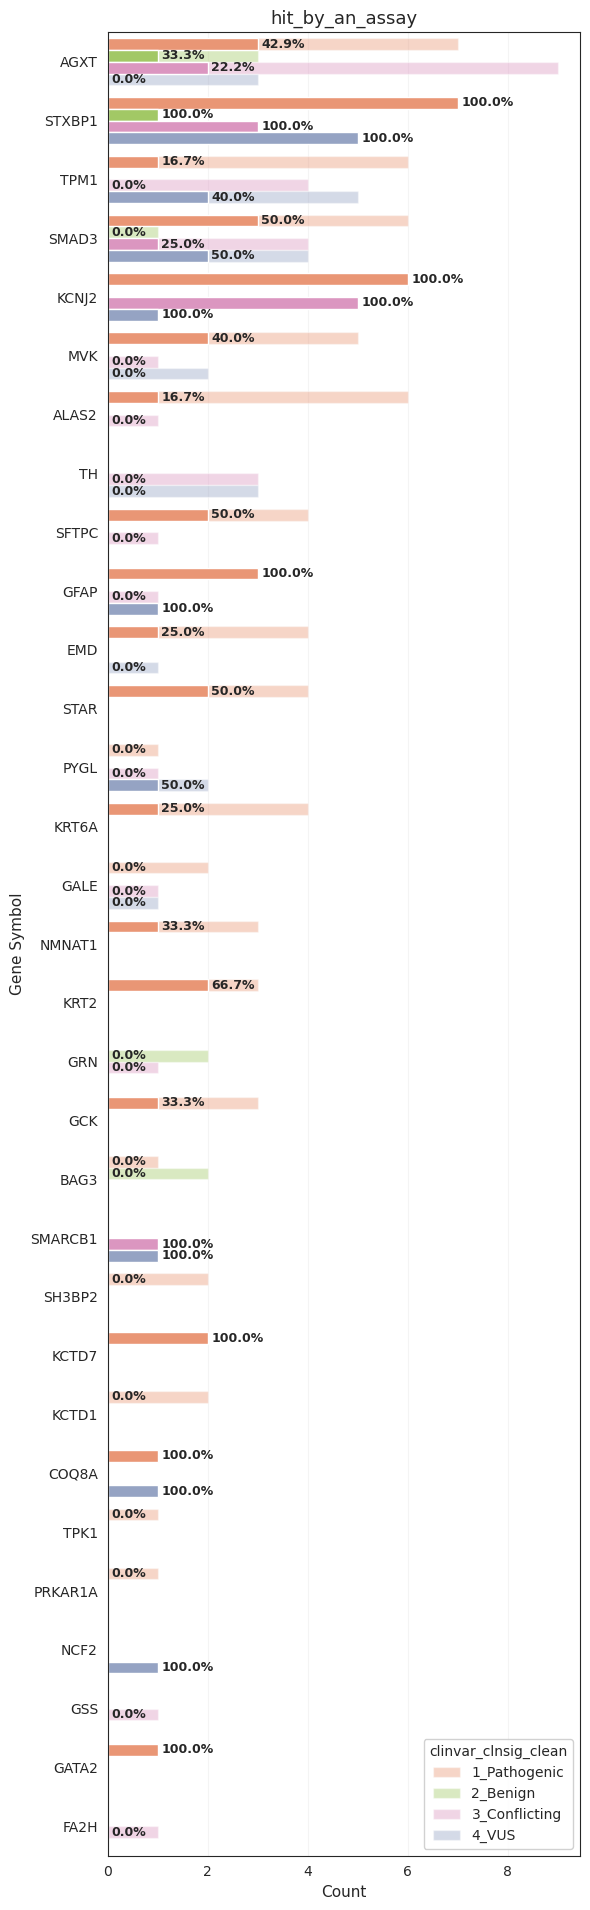

,symbol,clinvar_clnsig_clean,total_counts,hit_counts,hit_perc,total_counts_all
0,AGXT,1_Pathogenic,7,3,42.857143,22
1,AGXT,2_Benign,3,1,33.333333,22
2,AGXT,3_Conflicting,9,2,22.222222,22
3,AGXT,4_VUS,3,0,0.000000,22
4,STXBP1,1_Pathogenic,7,7,100.000000,16
5,STXBP1,2_Benign,1,1,100.000000,16
6,STXBP1,3_Conflicting,3,3,100.000000,16
7,STXBP1,4_VUS,5,5,100.000000,16
8,TPM1,1_Pathogenic,6,1,16.666667,15
9,TPM1,3_Conflicting,4,0,0.000000,15


In [162]:
plot_gene_level_summary(
    al_dual_img_ppi_intersect.with_columns(
        (
            (pl.col("dualipa_abun_change")==1)
            | (pl.col("Altered_95th_perc_both_batches_GFP"))
            | (pl.col("hit")==1)
        ).alias("hit_by_an_assay")
    ).filter(
        pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS"]) # "5_Others","6_No_ClinVar"
    ),
    assay="hit_by_an_assay", 
    cat="clinvar_clnsig_clean", 
    palette=palette_dict["clinvar_clnsig_clean"]
)

## Compare ClinVar label representation across assays

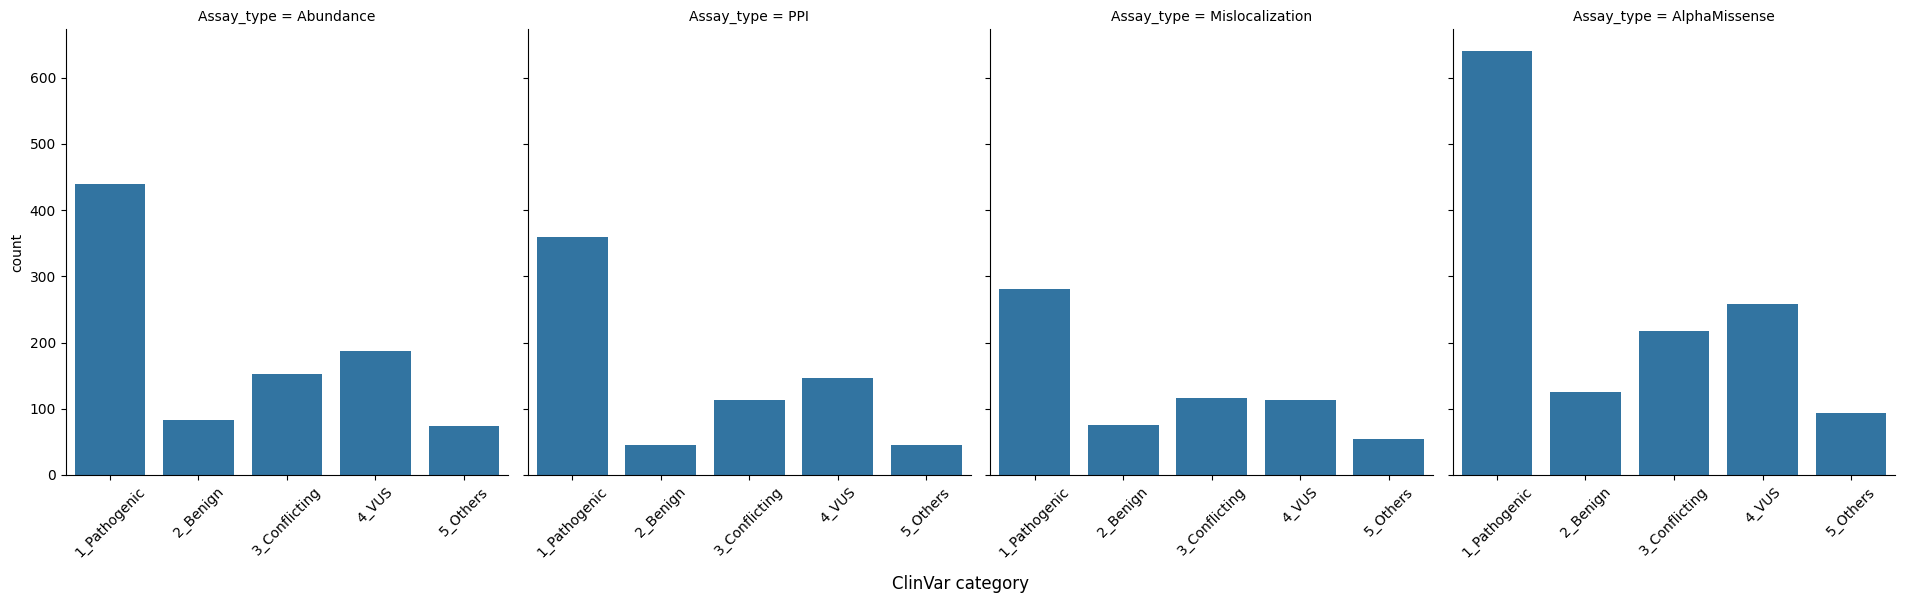

In [9]:
abun = scores.select(["clinvar_clnsig_clean", "abun_score"]).filter(
    ~pl.col("abun_score").is_null()
    ).select("clinvar_clnsig_clean").to_series().value_counts().sort("clinvar_clnsig_clean").with_columns(
        pl.lit("Abundance").alias("Assay_type")
    )

ppi = scores.select(["clinvar_clnsig_clean", "ppi_score"]).filter(
    ~pl.col("ppi_score").is_null()
    ).select("clinvar_clnsig_clean").to_series().value_counts().sort("clinvar_clnsig_clean").with_columns(
        pl.lit("PPI").alias("Assay_type")
    )

misloc = scores.select(["clinvar_clnsig_clean", "misloc_score"]).filter(
    ~pl.col("misloc_score").is_null()
    ).select("clinvar_clnsig_clean").to_series().value_counts().sort("clinvar_clnsig_clean").with_columns(
        pl.lit("Mislocalization").alias("Assay_type")
    )

ai = scores.select(["clinvar_clnsig_clean", "ai_score"]).filter(
    ~pl.col("ai_score").is_null()
    ).select("clinvar_clnsig_clean").to_series().value_counts().sort("clinvar_clnsig_clean").with_columns(
        pl.lit("AlphaMissense").alias("Assay_type")
    )

bar_df = pl.concat([abun, ppi, misloc, ai]).to_pandas()

g = sns.catplot(
    bar_df, kind="bar",
    x='clinvar_clnsig_clean', y='count', col="Assay_type",
    height=6, aspect=0.8,
)
g.set_xticklabels(rotation=45)

for ax in g.axes.flatten():
    ax.set_xlabel('')

g.fig.subplots_adjust(bottom=0.2)
g.fig.text(0.5, 0.01, "ClinVar category", ha="center", fontsize=12)
plt.show()

## How many variants are a hit in at least one assay?

In [10]:
# define thresholds
benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign")
abun_thresh = np.percentile(benign_scores.filter(~pl.col("abun_score").is_null()).select("abun_score").to_numpy(), 90)
misloc_thresh = np.percentile(benign_scores.filter(~pl.col("misloc_score").is_null()).select("misloc_score").to_numpy(), 90)
ppi_thresh = np.percentile(benign_scores.filter(~pl.col("ppi_score").is_null()).select("ppi_score").to_numpy(), 90)
ai_thresh = np.percentile(benign_scores.filter(~pl.col("ai_score").is_null()).select("ai_score").to_numpy(), 90)

scores = scores.with_columns(
    (pl.col("abun_score") > abun_thresh).alias("abun_hit"),
    (pl.col("misloc_score") > misloc_thresh).alias("misloc_hit"),
    (pl.col("ppi_score") > ppi_thresh).alias("ppi_hit"),
    (pl.col("ai_score") > ai_thresh).alias("ai_hit"),
)

scores = scores.with_columns(
    (pl.col("abun_hit").fill_null(False) | pl.col("misloc_hit").fill_null(False) | pl.col("ppi_hit").fill_null(False)).alias("any_hit_no_ai"),
    (pl.col("abun_hit").fill_null(False) | pl.col("misloc_hit").fill_null(False) | pl.col("ppi_hit").fill_null(False) | pl.col("ai_hit").fill_null(False)).alias("any_hit"),
)
scores.write_csv(f"{outputs_dir}/assay_scores.csv")

In [11]:
print(f"Abun: {abun_thresh}, Misloc: {misloc_thresh}, PPI: {ppi_thresh}, AI: {ai_thresh}")

Abun: 2.2254716325827633, Misloc: 0.9220841236645976, PPI: 0.5025974200756175, AI: 0.671775


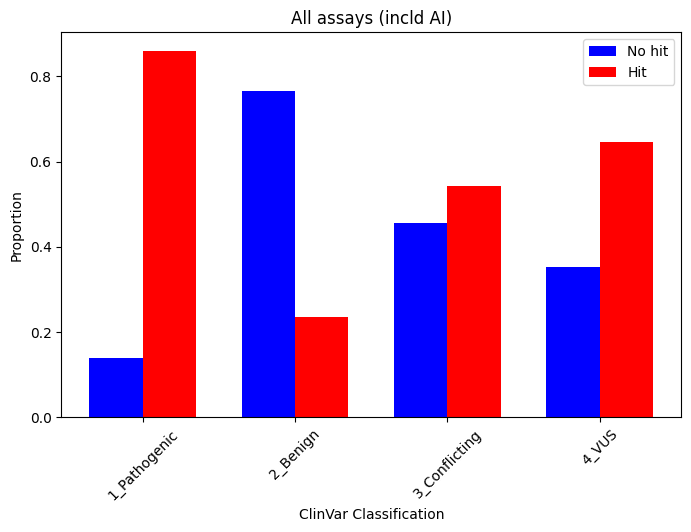

In [93]:
hit_rates = scores.group_by("clinvar_clnsig_clean").agg(
    pl.col("any_hit").value_counts(normalize=True)
).explode("any_hit").unnest("any_hit").pivot(
    values="proportion",
    index="clinvar_clnsig_clean",
    on="any_hit"
).filter(~pl.col("clinvar_clnsig_clean").is_in([None, "5_Others"])).sort(pl.col("clinvar_clnsig_clean"))

df_pd = hit_rates.to_pandas()

# Plot
x = np.arange(len(df_pd))  # Label locations
width = 0.35  # Bar width

fig, ax = plt.subplots(figsize=(8, 5))

# Plot bars
bars1 = ax.bar(x - width/2, df_pd["false"], width, label="No hit", color="blue")
bars2 = ax.bar(x + width/2, df_pd["true"], width, label="Hit", color="red")

# Labels and formatting
ax.set_xlabel("ClinVar Classification")
ax.set_ylabel("Proportion")
ax.set_xticks(x)
ax.set_xticklabels(df_pd["clinvar_clnsig_clean"], rotation=45)
ax.set_title("All assays (incld AI)")
ax.legend()

plt.show()

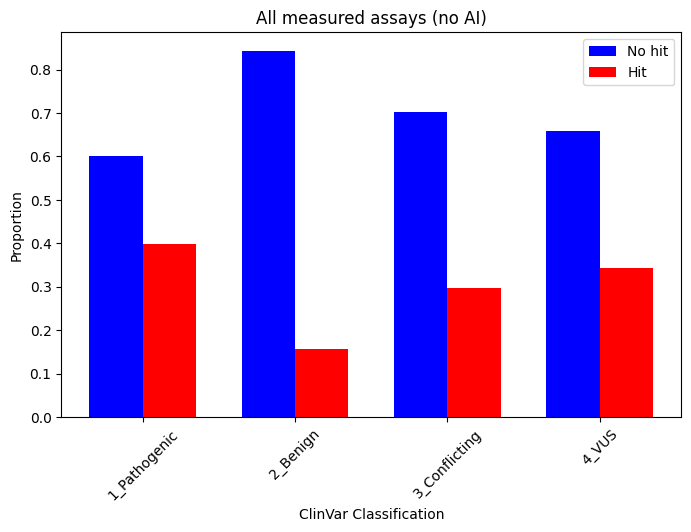

In [94]:
hit_rates = scores.group_by("clinvar_clnsig_clean").agg(
    pl.col("any_hit_no_ai").value_counts(normalize=True)
).explode("any_hit_no_ai").unnest("any_hit_no_ai").pivot(
    values="proportion",
    index="clinvar_clnsig_clean",
    on="any_hit_no_ai"
).filter(~pl.col("clinvar_clnsig_clean").is_in([None, "5_Others"])).sort(pl.col("clinvar_clnsig_clean"))

df_pd = hit_rates.to_pandas()

# Plot
x = np.arange(len(df_pd))  # Label locations
width = 0.35  # Bar width

fig, ax = plt.subplots(figsize=(8, 5))

# Plot bars
bars1 = ax.bar(x - width/2, df_pd["false"], width, label="No hit", color="blue")
bars2 = ax.bar(x + width/2, df_pd["true"], width, label="Hit", color="red")

# Labels and formatting
ax.set_xlabel("ClinVar Classification")
ax.set_ylabel("Proportion")
ax.set_xticks(x)
ax.set_xticklabels(df_pd["clinvar_clnsig_clean"], rotation=45)
ax.set_title("All measured assays (no AI)")
ax.legend()

plt.show()

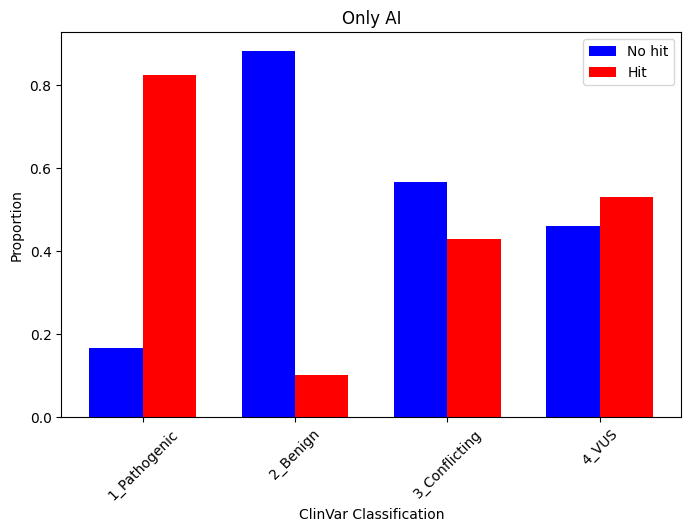

In [95]:
hit_rates = scores.group_by("clinvar_clnsig_clean").agg(
    pl.col("ai_hit").value_counts(normalize=True)
).explode("ai_hit").unnest("ai_hit").pivot(
    values="proportion",
    index="clinvar_clnsig_clean",
    on="ai_hit"
).filter(~pl.col("clinvar_clnsig_clean").is_in([None, "5_Others"])).sort(pl.col("clinvar_clnsig_clean"))

df_pd = hit_rates.to_pandas()

# Plot
x = np.arange(len(df_pd))  # Label locations
width = 0.35  # Bar width

fig, ax = plt.subplots(figsize=(8, 5))

# Plot bars
bars1 = ax.bar(x - width/2, df_pd["false"], width, label="No hit", color="blue")
bars2 = ax.bar(x + width/2, df_pd["true"], width, label="Hit", color="red")

# Labels and formatting
ax.set_xlabel("ClinVar Classification")
ax.set_ylabel("Proportion")
ax.set_xticks(x)
ax.set_xticklabels(df_pd["clinvar_clnsig_clean"], rotation=45)
ax.set_title("Only AI")
ax.legend()

plt.show()

## What is the overlap of hits across assays?

/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_16551/2705198571.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_16551/2705198571.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_16551/2705198571.py:4: FutureWarning: Downc

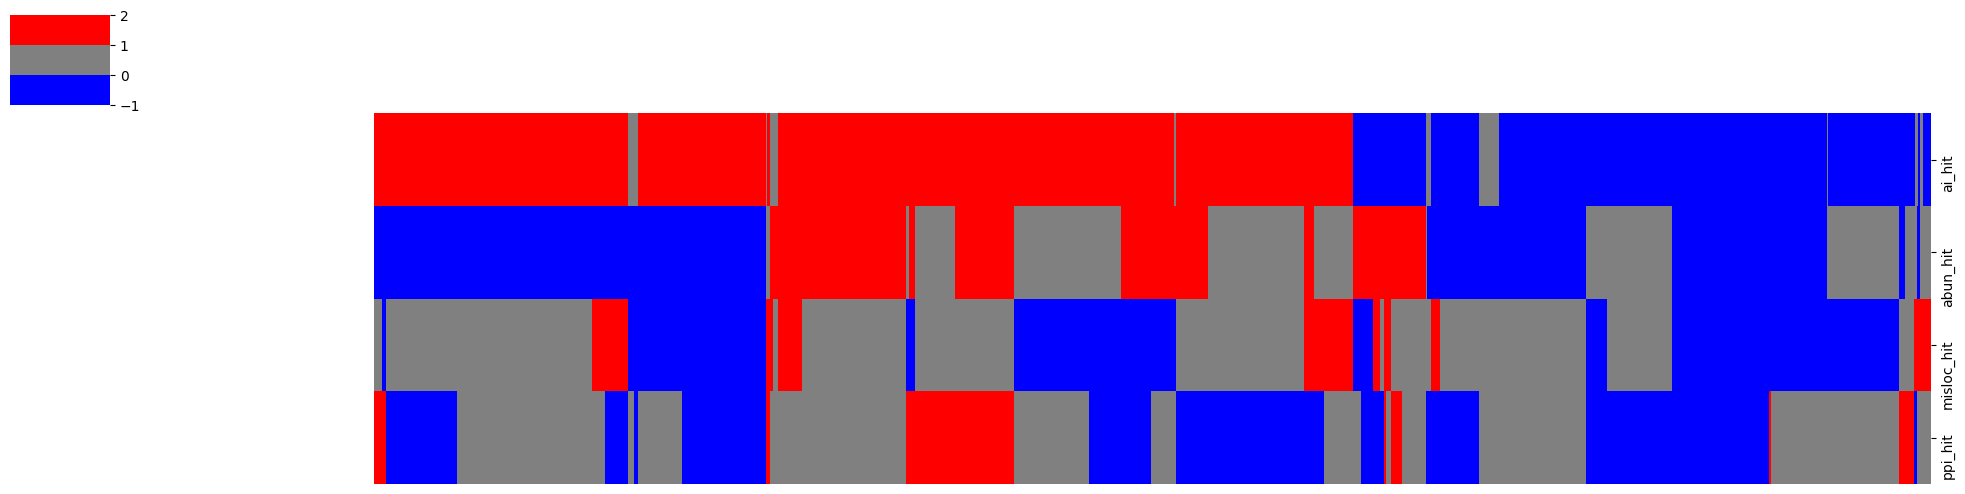

In [70]:
scores_hm = scores.select(["abun_hit", "misloc_hit", "ppi_hit", "ai_hit"]).to_pandas()
scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['ppi_hit'] = scores_hm['ppi_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['ai_hit'] = scores_hm['ai_hit'].replace({True: 1, False: -1, np.nan: 0})

cmap = colors.ListedColormap(['blue', 'grey', 'red'])
bounds = [-1, 0, 1, 2]
norm = colors.BoundaryNorm(bounds, cmap.N)

cg = sns.clustermap(scores_hm.transpose(), figsize=(20, 5), cmap=cmap, norm=norm, xticklabels=False)
cg.ax_row_dendrogram.set_visible(False)
cg.ax_col_dendrogram.set_visible(False)
plt.show()

/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_16551/572254314.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_16551/572254314.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_16551/572254314.py:4: FutureWarning: Downcast

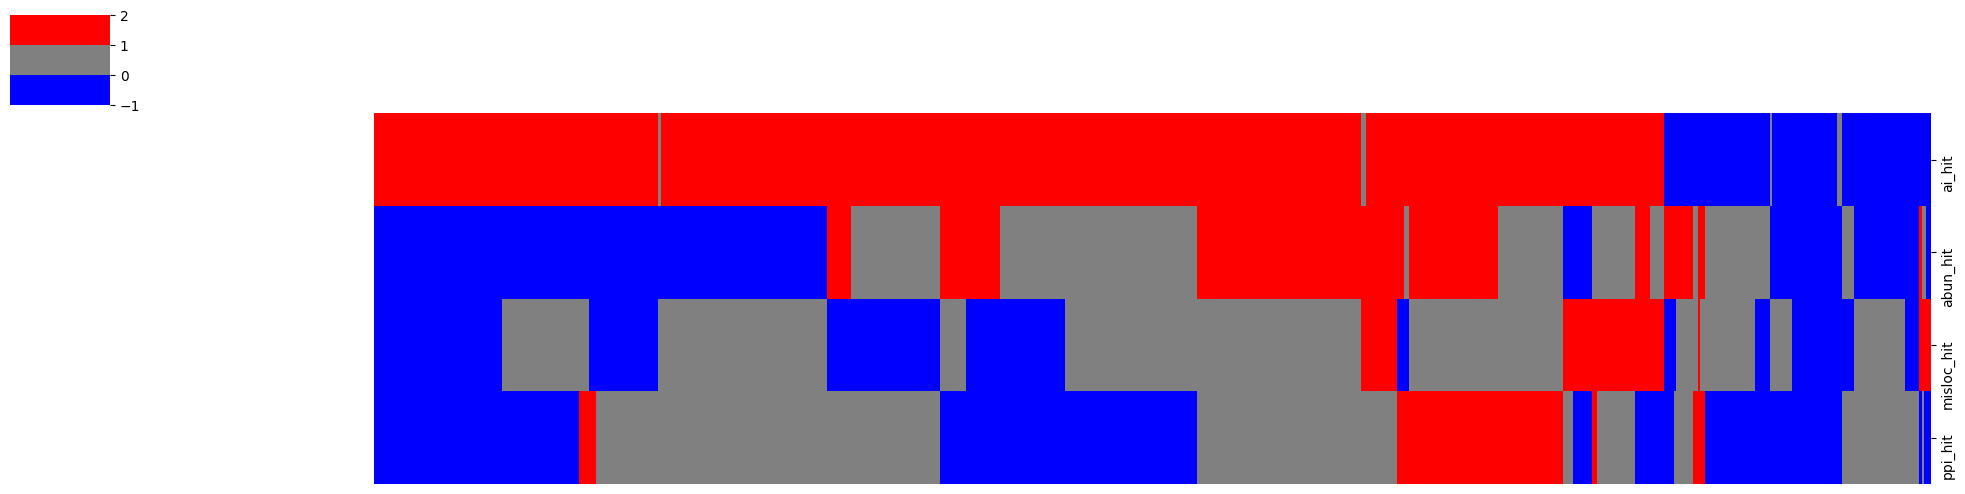

In [71]:
scores_hm = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").select(["abun_hit", "misloc_hit", "ppi_hit", "ai_hit"]).to_pandas()
scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['ppi_hit'] = scores_hm['ppi_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['ai_hit'] = scores_hm['ai_hit'].replace({True: 1, False: -1, np.nan: 0})

cmap = colors.ListedColormap(['blue', 'grey', 'red'])
bounds = [-1, 0, 1, 2]
norm = colors.BoundaryNorm(bounds, cmap.N)

cg = sns.clustermap(scores_hm.transpose(), figsize=(20, 5), cmap=cmap, norm=norm, xticklabels=False)
cg.ax_row_dendrogram.set_visible(False)
cg.ax_col_dendrogram.set_visible(False)
plt.show()

/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_16551/2761066996.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_16551/2761066996.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
/var/folders/g0/nk06fpgs01z6zmr4x7kvp0g80000gp/T/ipykernel_16551/2761066996.py:4: FutureWarning: Downc

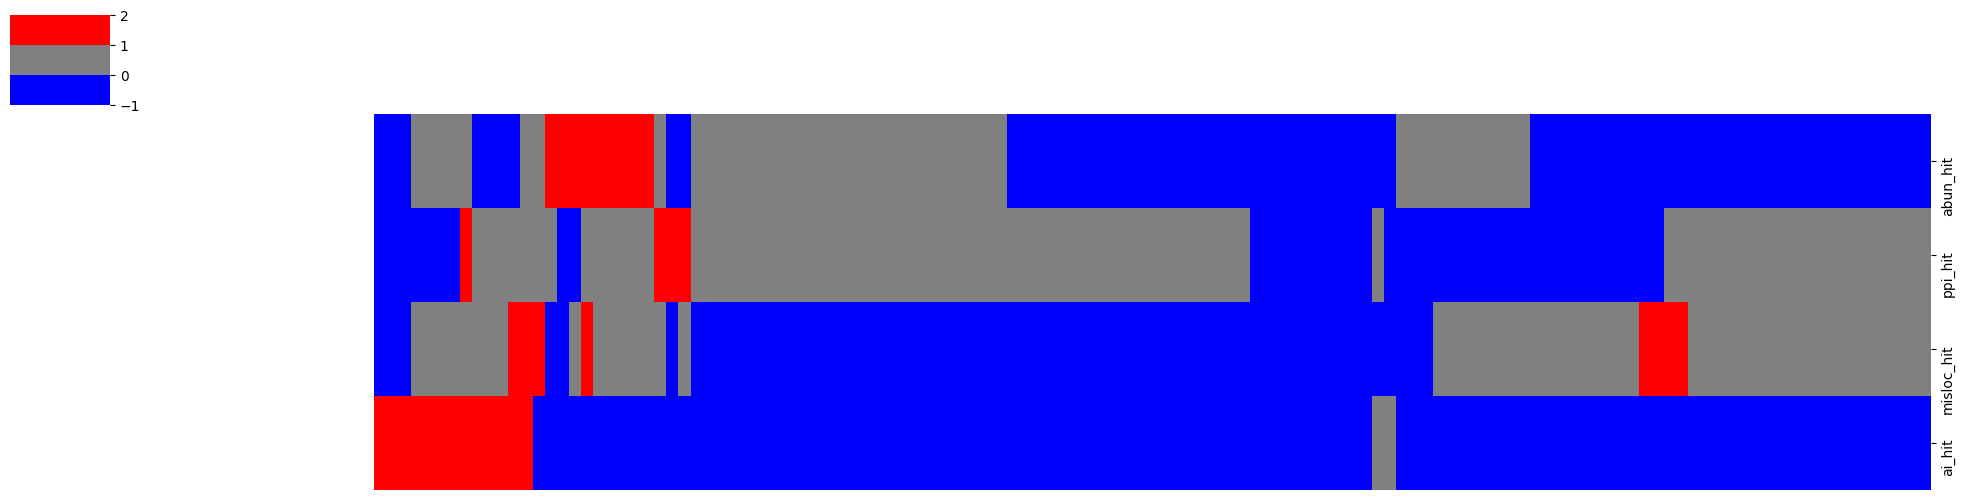

In [72]:
scores_hm = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").select(["abun_hit", "misloc_hit", "ppi_hit", "ai_hit"]).to_pandas()
scores_hm['abun_hit'] = scores_hm['abun_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['misloc_hit'] = scores_hm['misloc_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['ppi_hit'] = scores_hm['ppi_hit'].replace({True: 1, False: -1, np.nan: 0})
scores_hm['ai_hit'] = scores_hm['ai_hit'].replace({True: 1, False: -1, np.nan: 0})

cmap = colors.ListedColormap(['blue', 'grey', 'red'])
bounds = [-1, 0, 1, 2]
norm = colors.BoundaryNorm(bounds, cmap.N)

cg = sns.clustermap(scores_hm.transpose(), figsize=(20, 5), cmap=cmap, norm=norm, xticklabels=False)
cg.ax_row_dendrogram.set_visible(False)
cg.ax_col_dendrogram.set_visible(False)
plt.show()

All three: 1
PPI & Misloc: 5
PPI & Abun: 70
Misloc & Abun: 44
Hits in each assay: 320 for abundance, 123 for mislocalization, and 136 for ppi.


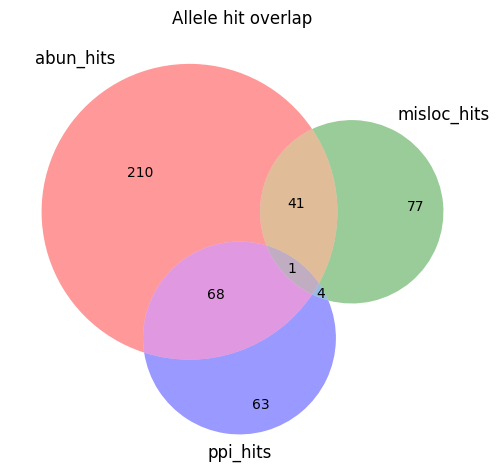

In [73]:
num_ppi_misloc_abun = scores.filter((pl.col("misloc_hit").fill_null(False)) &
                                    (pl.col("ppi_hit").fill_null(False)) &
                                    (pl.col("abun_hit").fill_null(False))).shape[0]

num_ppi_misloc = scores.filter((pl.col("misloc_hit").fill_null(False)) &
                               (pl.col("ppi_hit").fill_null(False)) ).shape[0]

num_ppi_abun = scores.filter((pl.col("abun_hit").fill_null(False)) &
                             (pl.col("ppi_hit").fill_null(False)) ).shape[0]

num_misloc_abun = scores.filter((pl.col("abun_hit").fill_null(False)) &
                                (pl.col("misloc_hit").fill_null(False)) ).shape[0]

print(f"All three: {num_ppi_misloc_abun}")
print(f"PPI & Misloc: {num_ppi_misloc}")
print(f"PPI & Abun: {num_ppi_abun}")
print(f"Misloc & Abun: {num_misloc_abun}")

# Show in Venn Diagram
set_abun = set(scores.filter(pl.col("abun_hit").fill_null(False)).select("allele_0").to_series())
set_misloc = set(scores.filter(pl.col("misloc_hit").fill_null(False)).select("allele_0").to_series())
set_ppi = set(scores.filter(pl.col("ppi_hit").fill_null(False)).select("allele_0").to_series())

print(f"Hits in each assay: {len(set_abun)} for abundance, {len(set_misloc)} for mislocalization, and {len(set_ppi)} for ppi.")

plt.figure(figsize=(6, 6))
venn3([set_abun, set_misloc, set_ppi], ('abun_hits', 'misloc_hits', 'ppi_hits'))
plt.title("Allele hit overlap")
plt.show()

In [74]:
set_abun.intersection(set_ppi, set_misloc)

set_ppi.intersection(set_misloc)

{'FBP1_Pro284Arg',
 'HPRT1_Phe74Leu',
 'KRT5_Gly476Asp',
 'KRT5_Lys404Glu',
 'NMNAT1_Arg237Leu'}

## Output gene lists for analysis

In [15]:
abun_background = scores.filter(~pl.col("abun_hit").is_null()).select("symbol").unique().write_csv(
    f"{outputs_dir}/gene_lists/abun_background.csv"
)
abun_hits = scores.filter(~pl.col("abun_hit").is_null()).filter(pl.col("abun_hit")).select("symbol").unique().write_csv(
    f"{outputs_dir}/gene_lists/abun_hits.csv"
)

misloc_background = scores.filter(~pl.col("misloc_hit").is_null()).select("symbol").unique().write_csv(
    f"{outputs_dir}/gene_lists/misloc_background.csv"
)
misloc_hits = scores.filter(~pl.col("misloc_hit").is_null()).filter(pl.col("misloc_hit")).select("symbol").unique().write_csv(
    f"{outputs_dir}/gene_lists/misloc_hits.csv"
)

ppi_background = scores.filter(~pl.col("ppi_hit").is_null()).select("symbol").unique().write_csv(
    f"{outputs_dir}/gene_lists/ppi_background.csv"
)
ppi_hits = scores.filter(~pl.col("ppi_hit").is_null()).filter(pl.col("ppi_hit")).select("symbol").unique().write_csv(
    f"{outputs_dir}/gene_lists/ppi_hits.csv"
)

We did not find any significant patterns with gene-level enrichment analysis. This is not overly surprising because the lists are very small so we are very underpowered to detect patterns. 